
# **📘 Air Temperature Forecasting**

# Air Temperature Forecasting using Machine Learning

## Project ID: PRAICP-1003-AirTempTS

## Business Case:
Develop a machine learning model to forecast future monthly mean air temperatures.

## Objective:
Build a model that predicts upcoming monthly temperatures based on historical data.

## Dataset:
Monthly air temperature dataset

# **1. Import Libraries**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

## **2. Load Dataset**

In [9]:
import zipfile

# Path to the ZIP file
zip_file_path = "/content/PRAICP-1003-AirTempTS.zip"
# Name of the CSV file inside the ZIP
csv_file_in_zip = "Data/surface-air-temperature-monthly-mean.csv"

# Extract the CSV file from the ZIP archive
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extract(csv_file_in_zip, path="/content/") # Extract to /content/ directory

# Now, read the extracted CSV file
df = pd.read_csv(f"/content/{csv_file_in_zip}")

df.head()

,month,mean_temp
0,1982-01,25.9
1,1982-02,27.1
2,1982-03,27.2
3,1982-04,27.0
4,1982-05,28.0


# **3. Data Understanding**

In [12]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 462 entries, 0 to 461
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   month      462 non-null    object 
 1   mean_temp  462 non-null    float64
dtypes: float64(1), object(1)
memory usage: 7.3+ KB


,mean_temp
count,462.000000
mean,27.665152
std,0.808186
min,25.400000
25%,27.100000
50%,27.700000
75%,28.300000
max,29.500000


# **📊 4. Convert Month to Datetime**

In [16]:
df['month'] = pd.to_datetime(df['month'])
df.set_index('month', inplace=True)

df.head()

,mean_temp
month,
1982-01-01,25.9
1982-02-01,27.1
1982-03-01,27.2
1982-04-01,27.0
1982-05-01,28.0


# **📈 5. Visualization**

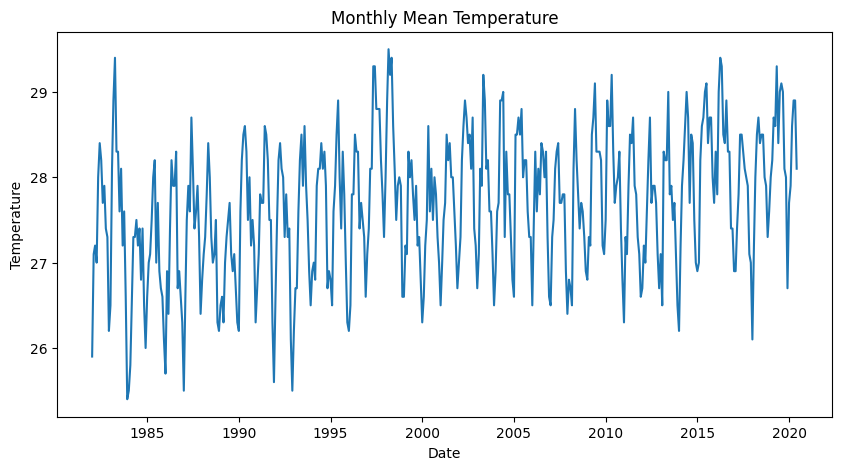

In [19]:
plt.figure(figsize=(10,5))
plt.plot(df['mean_temp'])
plt.title("Monthly Mean Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.show()

# **6**. Create Time Features

In [20]:
df['month_num'] = df.index.month
df['year'] = df.index.year

df.head()

,mean_temp,month_num,year
month,,,
1982-01-01,25.9,1,1982
1982-02-01,27.1,2,1982
1982-03-01,27.2,3,1982
1982-04-01,27.0,4,1982
1982-05-01,28.0,5,1982


# **8. Model Training**

In [23]:
X = df[['month_num', 'year']]
y = df['mean_temp']

model = LinearRegression()
model.fit(X, y)

LinearRegression()

# **9. Forecast Next 12 Months**

In [24]:
future_dates = pd.date_range(start=df.index[-1], periods=13, freq='M')[1:]

future_df = pd.DataFrame()
future_df['month_num'] = future_dates.month
future_df['year'] = future_dates.year

predictions = model.predict(future_df)

future_df['Predicted_Temp'] = predictions
future_df.index = future_dates

future_df

/tmp/ipykernel_11194/2275949609.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  future_dates = pd.date_range(start=df.index[-1], periods=13, freq='M')[1:]


,month_num,year,Predicted_Temp
2020-07-31,7,2020,28.118670
2020-08-31,8,2020,28.104432
2020-09-30,9,2020,28.090194
2020-10-31,10,2020,28.075957
2020-11-30,11,2020,28.061719
2020-12-31,12,2020,28.047481
2021-01-31,1,2021,28.228058
2021-02-28,2,2021,28.213820
2021-03-31,3,2021,28.199583
2021-04-30,4,2021,28.185345


# **📊 10. Plot Predictions**

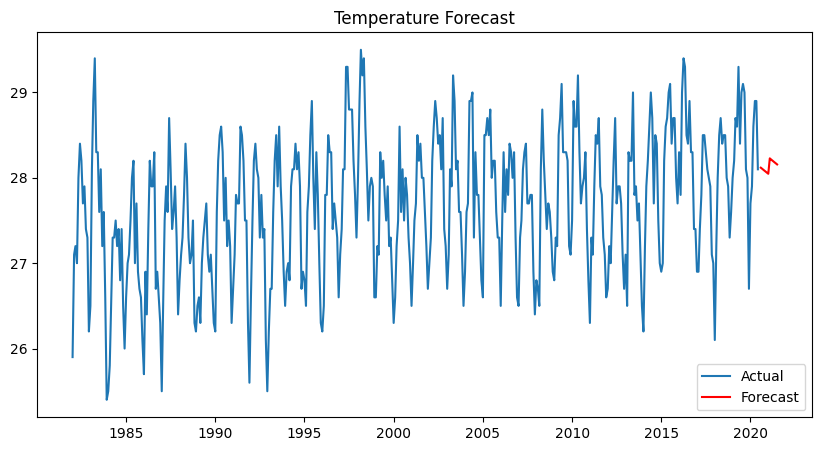

In [27]:
plt.figure(figsize=(10,5))

plt.plot(df['mean_temp'], label="Actual")
plt.plot(future_df['Predicted_Temp'], label="Forecast", color='red')

plt.legend()
plt.title("Temperature Forecast")
plt.show()

# **11. Save Output**

In [28]:
future_df.to_csv("forecast_output.csv")
print("Forecast saved!")

Forecast saved!


# **📌 Project Summary **

This project focuses on forecasting monthly mean air temperature using machine learning techniques. The objective is to build a predictive model that can estimate future temperature values based on historical data. The dataset contains two main features: Month and Mean Temperature.

The data is preprocessed by converting the month column into a datetime format and extracting useful features such as month and year. A simple and efficient Linear Regression model is used to learn the relationship between time and temperature.

The model is trained on historical data and used to predict temperatures for future months. The results are visualized using graphs to compare actual and predicted values. This project demonstrates how time series data can be analyzed and forecasted using basic machine learning methods.

Overall, the model provides a simple and effective solution for temperature forecasting and can be further improved using advanced techniques like ARIMA or LSTM.
